# Quality assessment of the 2D reference labels

**Reviewer question:** *"The 2D reference labels are the foundation of the experiments. Could
the authors provide a quality assessment of these 2D reference labels?"*

`label_qa.py` measures the delivered labels of both sites and writes a per-tile summary and a
per-polygon issue log. Everything shown below is read back from those two CSVs, so every number
on this page is reproducible by re-running section 2.

**The classification target is growth form** — forb, grass, shrub, mallee, woody debris — which
is defined by plant architecture: woodiness, branching, stem persistence. It is *not* a height
stratification. A chenopod shrub 15 cm tall is a shrub. This matters for what counts as evidence
about the labels, and section 8 turns on it.

**No repeat annotation was made and none is claimed.** Section 11 says what is measured in its
place and what that can and cannot support.

| Measured | Not measured |
|---|---|
| Coverage, class balance, geometry integrity, boundary ambiguity | **Annotation reproducibility** — whether a second annotator would draw and class the same thing. That needs a second opinion this step does not have. |
| Preservation through rasterisation and through the 1 cm → 5 cm downsample, as IoU per class | **Accuracy against ground truth** — no field data are available for these tiles. |
| **Registration** — whether a label and a predictor pixel at the same row and column are the same ground, which decides whether the labels are the right *reference* at all (section 7) | **Whether a class is "too short"** — growth form does not imply a height, so height cannot falsify a label here. |
| **Delineation sensitivity** — how much of each class a 5 cm shift in the outline could move, which bounds what a second annotator could change (section 11) | |
| Separation of the classes on LiDAR height, a measurement never used to build the labels | |


---
## 1. Setup

Paths are written in Windows form and resolved by `wsl_path()` from `label_qa.py`: it returns
`/mnt/<drive>/...` when the drive is mounted and falls back to a `/tmp/wsl_drive_<drive>` mirror
when it is not.


In [ ]:
import subprocess
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def find_repo_root(start: Path) -> Path:
    marker = Path('phase_3_2D_imagery_prep/step_3_label_quality/label_qa.py')
    for candidate in [start, *start.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f'Could not locate repository root from {start}')


REPO_ROOT = find_repo_root(Path.cwd().resolve())
STEP_DIR = REPO_ROOT / 'phase_3_2D_imagery_prep' / 'step_3_label_quality'
if str(STEP_DIR) not in sys.path:
    sys.path.insert(0, str(STEP_DIR))

from label_qa import CANOPY_PERCENTILE, CLASS_LABELS, DEFAULT_BOUNDARY_M, wsl_path

ID_BY_NAME = {name: struct_id for struct_id, name in CLASS_LABELS.items()}
BOUNDARY_CM = DEFAULT_BOUNDARY_M * 100
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print(f'Repo root: {REPO_ROOT}')


Repo root: /home/uqlsoto1/code_phd/fvc_structure


### Chart style

One palette for the whole notebook: categorical slots in fixed order (never cycled), recessive
grid and axes, ink colours for all text so identity is never carried by colour alone.


In [2]:
SURFACE = '#fcfcfb'
INK = '#0b0b0b'
INK_2 = '#52514e'
MUTED = '#898781'
GRID = '#e1e0d9'
AXIS = '#c3c2b7'
# Categorical slots, fixed order. Validated for CVD separation as a set.
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']

mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'sans-serif', 'font.size': 10,
    'text.color': INK, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8,
    'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'figure.dpi': 120,
})


def tidy(ax, xgrid=True):
    """Recessive grid on the value axis only, and nothing else."""
    ax.set_axisbelow(True)
    ax.grid(axis='x' if xgrid else 'y', alpha=1.0)
    ax.grid(axis='y' if xgrid else 'x', visible=False)
    ax.tick_params(length=0)
    return ax

---
## 2. Run both sites

These are **two different sites**, not two plots of one: `site1_1_DD0001` at the medium
condition and `site2_1_DD0011` at the low condition, named as they are throughout phases 2, 4
and 5. `shp_subdir` differs between them — DD0001 uses `annotations_shp` (plural), DD0011 uses
`annotation_shp`. Set `FORCE_RERUN = True` to recompute.


In [ ]:
SITES = [
    {'site': 'site1_1_DD0001', 'condition': 'Medium', 'shp_subdir': 'annotations_shp'},
    {'site': 'site2_1_DD0011', 'condition': 'Low',    'shp_subdir': 'annotation_shp'},
]
FORCE_RERUN = False


def paths(cfg):
    base = wsl_path(rf"D:\paper2\data\calperumResearch\{cfg['site']}")
    mask = base / 'imagery' / 'inputs' / 'masks' / 'tiles_3072' / 'raw' / 'structure_class'
    raster = mask / 'annotation_raster'
    pred = base / 'imagery' / 'inputs' / 'predictors' / 'tiles_3072'
    return {
        'base': base, 'mask': mask,
        'shp': mask / cfg['shp_subdir'],
        'raster': raster,
        'coarse': raster / 'downsample_5cm_nearest',
        # DD0001 keeps the predictor stack under multispec/res_05, DD0011 directly here.
        'image': next((d for d in (pred / 'multispec' / 'res_05' / 'stacked', pred / 'stacked')
                       if d.exists()), None),
        'las': base / 'lidar' / 'clipped' / 'raster' / 'z_norm' / 'csf',
        'out': base / 'lidar' / 'clipped' / 'validation' / 'label_quality',
    }


DATA = {}
for cfg in SITES:
    p = paths(cfg)
    summary_csv = p['out'] / f"{cfg['site']}_qa_summary.csv"
    if FORCE_RERUN or not summary_csv.exists():
        cmd = [sys.executable, str(STEP_DIR / 'label_qa.py'),
               '--site', cfg['site'], '--site-condition', cfg['condition'],
               '--shp-dir', str(p['shp']), '--raster-dir', str(p['raster']),
               '--downsampled-dir', str(p['coarse']), '--las-dir', str(p['las']),
               *(['--image-dir', str(p['image'])] if p['image'] else []),
               '--output-dir', str(p['out'])]
        result = subprocess.run(cmd, text=True, capture_output=True)
        if result.returncode != 0:
            print(result.stderr[-3000:], file=sys.stderr)
            raise RuntimeError(f"label_qa.py failed for {cfg['site']}")
    summary = pd.read_csv(summary_csv)
    DATA[cfg['condition']] = {
        **cfg, 'paths': p,
        'per_tile': summary[summary['Tile'] != 'Average'].copy(),
        'avg': summary[summary['Tile'] == 'Average'].iloc[0],
        'issues': pd.read_csv(p['out'] / f"{cfg['site']}_qa_issues.csv"),
    }
    d = DATA[cfg['condition']]
    print(f"{cfg['condition']:>7}  {cfg['site']}  {len(d['per_tile'])} tiles, "
          f"{len(d['issues'])} issues logged")

CONDITIONS = list(DATA)
COLOUR = dict(zip(CONDITIONS, SERIES))


 Medium  site1_1_DD0001  15 tiles, 1856 issues logged
    Low  site2_1_DD0011  15 tiles, 5679 issues logged


---
## 3. The answer, in one table

Built from the CSVs, so it cannot drift from the measurements. ⚠ marks a value that needs
explaining before it is reported — each is worked through in section 10.


In [ ]:
def fmt_range(row, prefix, alarm=0.50):
    vals = {n: row.get(f'{prefix} {n}') for n in CLASS_LABELS.values()}
    vals = {n: v for n, v in vals.items() if pd.notna(v)}
    if not vals:
        return 'not measured'
    lo_name, lo = min(vals.items(), key=lambda kv: kv[1])
    text = f'{lo:.2f}–{max(vals.values()):.2f}'
    return f'{text}  ⚠ {lo_name} {lo:.3f}' if lo < alarm else text


rows = []
for cond in CONDITIONS:
    d = DATA[cond]
    a, tiles = d['avg'], d['per_tile']
    # Descriptive only: growth form implies no height, so there is no verdict to report.
    tallest = max(((n, a.get(f'P95 Znorm {n} (m)')) for n in CLASS_LABELS.values()
                   if pd.notna(a.get(f'P95 Znorm {n} (m)'))),
                  key=lambda kv: kv[1], default=None)
    misaligned = int((tiles['5 cm grid offset (cm)'] > 0).sum())
    gsd, ratio = a.get('Imagery GSD (cm)'), a.get('Label cells per imagery pixel')
    rows.append({
        'Site': f"{cond} ({d['site'].split('_')[-1]})",
        'Tiles': len(tiles),
        'Tile area labelled': f"{a['Labelled area (%)']:.1f}%",
        'Polygons per tile': f"{a['Polygons']:.0f} (median {a['Median polygon area (m2)']:.3f} m²)",
        'Invalid geometries': f"{a['Invalid geometries']:.1f}/tile, "
                              f"{'all' if a['Invalid geometries'] == a['Repairable by buffer(0)'] else 'some'} repairable",
        'Duplicates / zero-area': f"{a['Duplicate geometries']:.0f} / {a['Empty or zero-area']:.0f}",
        'Cross-class overlap': f"{a['Cross-class overlap (%)']:.3f}% of labelled area",
        'IoU vector → 1 cm': fmt_range(a, 'IoU raster'),
        'IoU 1 cm → 5 cm': fmt_range(a, 'IoU 5 cm')
                           + (f'  ⚠ {misaligned}/{len(tiles)} tiles grid-misaligned' if misaligned else ''),
        'Predictor grid the labels are read against': 'not measured (no imagery matched)'
            if pd.isna(gsd) else f'{gsd:.1f} cm, {ratio:.2f} label cells per pixel, '
                                 f"origin {a['Imagery grid offset (cm)']:.2f} cm off the label grid",
        'IoU on the predictor grid': fmt_range(a, 'IoU imagery grid', alarm=0.95),
        f'Delineation IoU at ±{BOUNDARY_CM:.0f} cm': fmt_range(a, 'Delineation IoU'),
        f'Labelled area within {BOUNDARY_CM:.0f} cm of another class':
            f"{a['Labelled area near a class boundary (%)']:.1f}%",
        'Height AUC vs other classes': fmt_range(a, 'Height AUC', alarm=0.0),
        f'Top-of-canopy P{CANOPY_PERCENTILE}': 'not measured (no LAS matched)' if tallest is None
            else f'{tallest[0].lower()} tallest at {tallest[1]:.2f} m (descriptive)',
        'Reproducibility': 'not measured — see section 11',
    })

answer = pd.DataFrame(rows).set_index('Site').T
answer.columns.name = None
display(answer)


,Medium (DD0001),Low (DD0011)
Tiles,15,15
Tile area labelled,20.2%,35.1%
Polygons per tile,408 (median 0.076 m²),413 (median 0.278 m²)
Invalid geometries,"7.6/tile, all repairable","0.8/tile, all repairable"
Duplicates / zero-area,0 / 0,0 / 0
Cross-class overlap,0.021% of labelled area,0.161% of labelled area
IoU vector → 1 cm,0.85–0.98,0.01–0.98 ⚠ Woody debris 0.014
IoU 1 cm → 5 cm,0.68–0.95 ⚠ 13/15 tiles grid-misaligned,0.99–1.00
Top-of-canopy P95,mallee tallest at 1.42 m (descriptive),shrub tallest at 0.30 m (descriptive)
Reproducibility,not measured — needs a repeat delineation,not measured — needs a repeat delineation


---
## 4. Coverage and class balance

The annotation is sparse polygon work, not wall-to-wall, so the first thing to state is how much
of each tile carries a reference value at all. The class mix then explains most of what follows:
the two sites share almost no classes, and each is dominated by one.


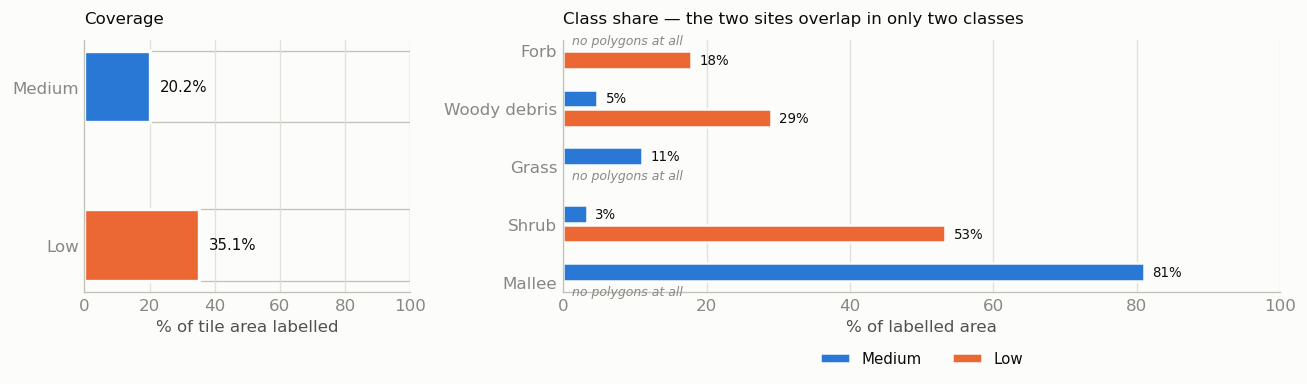

Classes present in both sites: Woody debris, Shrub


In [5]:
names = list(CLASS_LABELS.values())
fig, (ax_cov, ax_mix) = plt.subplots(
    1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1, 2.2]})

# Left: how much of a tile carries a reference value at all.
y_site = np.arange(len(CONDITIONS))
cov = [DATA[c]['avg']['Labelled area (%)'] for c in CONDITIONS]
ax_cov.barh(y_site, cov, height=0.45, color=[COLOUR[c] for c in CONDITIONS],
            edgecolor=SURFACE, linewidth=2)
ax_cov.barh(y_site, [100] * len(y_site), height=0.45, color='none',
            edgecolor=AXIS, linewidth=0.8, zorder=0)
for i, v in enumerate(cov):
    ax_cov.text(v + 3, i, f'{v:.1f}%', va='center', ha='left', color=INK, fontsize=9)
ax_cov.set_yticks(y_site, CONDITIONS)
ax_cov.invert_yaxis()
ax_cov.set_xlim(0, 100)
ax_cov.set_xlabel('% of tile area labelled')
ax_cov.set_title('Coverage', loc='left', fontsize=10, pad=10)
tidy(ax_cov)

# Right: class share, grouped by site. Hue means the site here and everywhere
# else in this notebook; classes are named on the axis, never coloured.
y = np.arange(len(names))
h = 0.34
for k, cond in enumerate(CONDITIONS):
    vals = [DATA[cond]['avg'].get(f'{n} area (%)') for n in names]
    polys = [DATA[cond]['avg'].get(f'{n} polygons', 0) for n in names]
    pos = y + (k - (len(CONDITIONS) - 1) / 2) * h
    shown = [(p, v) for p, v, n in zip(pos, vals, polys) if n]
    if shown:
        ax_mix.barh([p for p, _ in shown], [v for _, v in shown], height=h * 0.88,
                    color=COLOUR[cond], label=cond, edgecolor=SURFACE, linewidth=1.5)
    for p, v, n in zip(pos, vals, polys):
        if n:
            ax_mix.text(v + 1.2, p, f'{v:.0f}%', va='center', ha='left', color=INK, fontsize=8)
        else:
            ax_mix.text(1.2, p, 'no polygons at all', va='center', ha='left',
                        color=MUTED, fontsize=7.5, style='italic')
ax_mix.set_yticks(y, names)
ax_mix.invert_yaxis()
ax_mix.set_xlim(0, 100)
ax_mix.set_xlabel('% of labelled area')
ax_mix.set_title('Class share — the two sites overlap in only two classes',
                 loc='left', fontsize=10, pad=10)
ax_mix.legend(ncols=2, loc='upper center', bbox_to_anchor=(0.5, -0.18), fontsize=9)
tidy(ax_mix)
plt.tight_layout()
plt.show()

shared = [n for n in names if all(DATA[c]['avg'].get(f'{n} polygons', 0) for c in CONDITIONS)]
print('Classes present in both sites:', ', '.join(shared))

---
## 5. Preservation, as IoU

The labels pass through two lossy transformations before a model sees them, and each gets one
IoU per class. **1.000 is lossless.**

| | Compares | What a shortfall means |
|---|---|---|
| **vector → 1 cm** | polygons rasterised exactly (centroid rule) vs the delivered 1 cm raster | the cost of `all_touched=True`, which dilates each polygon by up to one 1 cm ring, plus resolving overlaps by draw order |
| **1 cm → 5 cm** | majority class of each 5 cm cell's twenty-five 1 cm sub-pixels vs the delivered 5 cm raster | how much the downsample changed the reference the models actually consume |

Nodata counts as a category in the majority rule — otherwise a single labelled 1 cm pixel in
twenty-five would make the whole cell that class, which no downsampling rule would deliver.


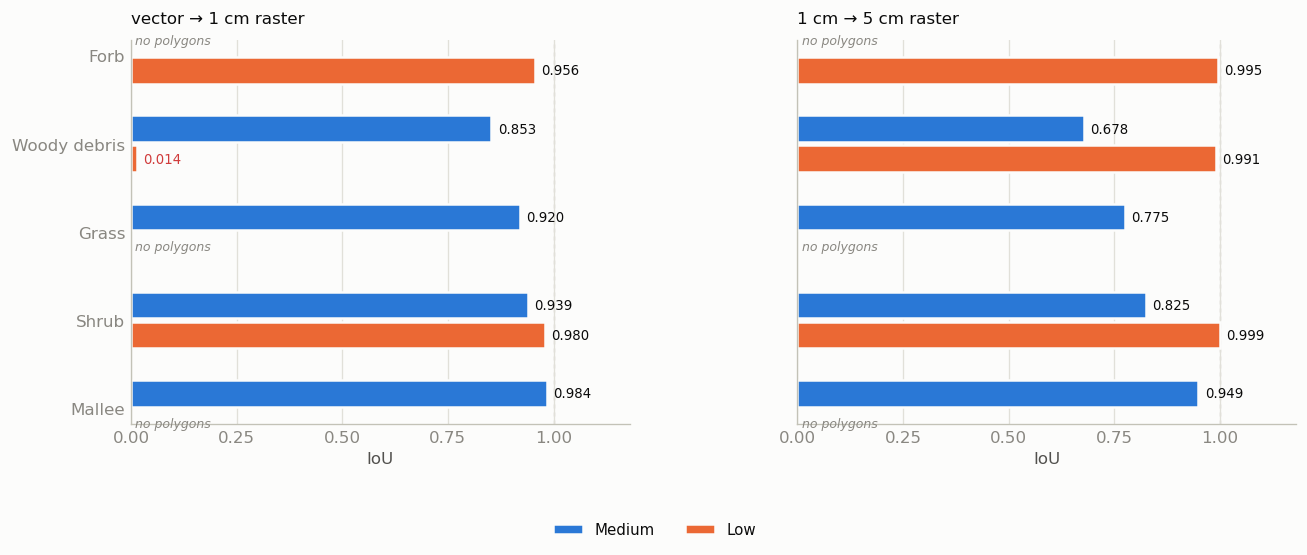

In [6]:
present = [n for n in CLASS_LABELS.values()
            if any(DATA[c]['avg'].get(f'{n} polygons', 0) for c in CONDITIONS)]
panels = [('IoU raster', 'vector → 1 cm raster'), ('IoU 5 cm', '1 cm → 5 cm raster')]

fig, axes = plt.subplots(1, 2, figsize=(11, 0.55 * len(present) + 2.1), sharey=True)
y = np.arange(len(present))
h = 0.34

for ax, (prefix, title) in zip(axes, panels):
    for k, cond in enumerate(CONDITIONS):
        vals = [DATA[cond]['avg'].get(f'{prefix} {n}') for n in present]
        offset = (k - (len(CONDITIONS) - 1) / 2) * h
        pos = y + offset
        finite = [(p, v) for p, v in zip(pos, vals) if pd.notna(v)]
        if finite:
            ax.barh([p for p, _ in finite], [v for _, v in finite], height=h * 0.88,
                    color=COLOUR[cond], label=cond, edgecolor=SURFACE, linewidth=1.5)
        for p, v in zip(pos, vals):
            if pd.isna(v):
                ax.text(0.01, p, 'no polygons', va='center', ha='left',
                        color=MUTED, fontsize=7.5, style='italic')
            else:
                ax.text(v + 0.015, p, f'{v:.3f}', va='center', ha='left',
                        color=INK if v >= 0.5 else '#d03b3b', fontsize=8)
    ax.axvline(1.0, color=AXIS, linewidth=0.8, linestyle=(0, (3, 3)), zorder=0)
    ax.set_xlim(0, 1.18)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_title(title, loc='left', fontsize=10, pad=10)
    ax.set_xlabel('IoU')
    tidy(ax)

axes[0].set_yticks(y, present)
axes[0].invert_yaxis()
axes[0].legend(ncols=2, loc='upper center', bbox_to_anchor=(1.05, -0.22), fontsize=9)
plt.tight_layout()
plt.show()

Two numbers do not belong with the others, and they are unrelated to each other.

- **Low site, Woody debris, vector → 1 cm = 0.014.** `all_touched` costs a class a few percent,
  never this. Section 10.2.
- **Medium site, 1 cm → 5 cm = 0.68–0.95** where the low site is 0.99–1.00. Section 10.1.


---
## 6. Why the medium site's 5 cm IoU falls

A 3072 px tile at 1 cm is 30.72 m, and 30.72 / 0.05 = 614.4 is not an integer, so
`gdalwarp -tr 0.05` in `2_3_downsampling_labels.py` cannot land on the 1 cm grid — it snaps to
614 cells and shifts the origin. Because the same call passes `-srcnodata 255`, nearest
resampling onto the shifted grid takes the nearest *valid* source pixel in preference to a nodata
one, so sparse classes are dilated rather than sampled.

The chart is the cause beside the effect: every tile whose grid happens to land on the 1 cm grid
gains no area, and every tile that does not gains ten percent or more.


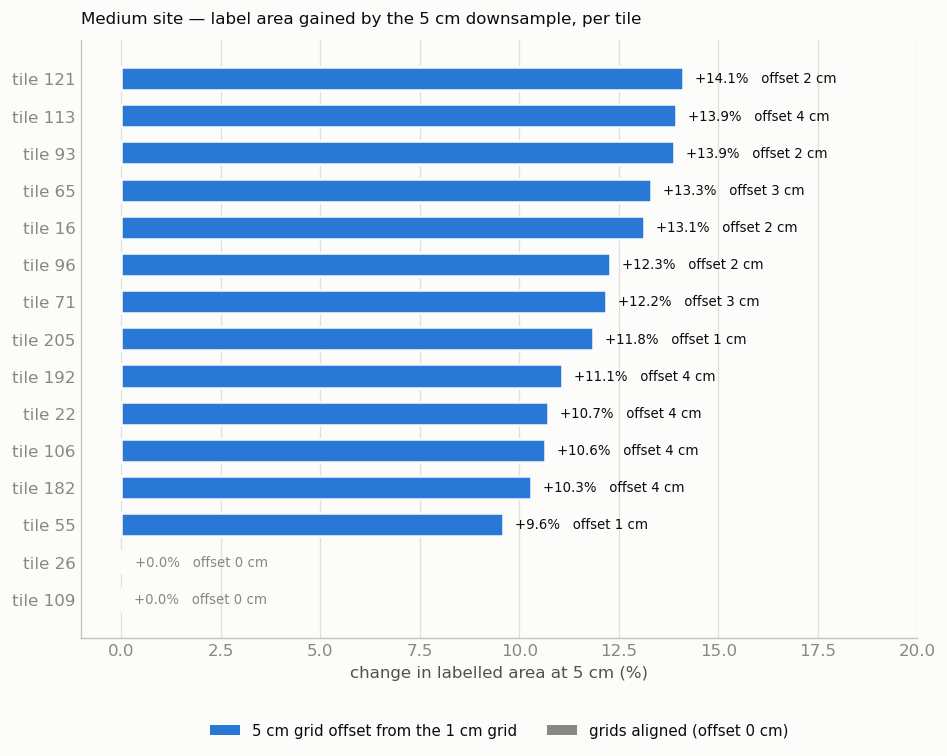

Low site, for contrast: offset 0 cm and +0.12% area change on all 15 tiles.


In [7]:
d = DATA['Medium']
tiles = d['per_tile'].copy()
tiles['offset'] = tiles['5 cm grid offset (cm)']
tiles['change'] = tiles['Labelled area change at 5 cm (%)']
tiles = tiles.sort_values('change')
aligned = tiles['offset'] == 0

fig, ax = plt.subplots(figsize=(8, 0.32 * len(tiles) + 1.6))
y = np.arange(len(tiles))
ax.barh(y, tiles['change'], height=0.62, edgecolor=SURFACE, linewidth=1.5,
        color=[MUTED if a else SERIES[0] for a in aligned])
for i, (chg, off) in enumerate(zip(tiles['change'], tiles['offset'])):
    ax.text(chg + 0.3, i, f'{chg:+.1f}%   offset {off:.0f} cm', va='center', ha='left',
            color=MUTED if off == 0 else INK, fontsize=8)
ax.set_yticks(y, [f'tile {t}' for t in tiles['Tile']])
ax.set_xlim(-1, 20)
ax.set_xlabel('change in labelled area at 5 cm (%)')
ax.set_title('Medium site — label area gained by the 5 cm downsample, per tile',
             loc='left', fontsize=10, pad=10)
handles = [mpl.patches.Patch(facecolor=SERIES[0], label='5 cm grid offset from the 1 cm grid'),
           mpl.patches.Patch(facecolor=MUTED, label='grids aligned (offset 0 cm)')]
ax.legend(handles=handles, ncols=2, loc='upper center', bbox_to_anchor=(0.5, -0.12), fontsize=9)
tidy(ax)
plt.tight_layout()
plt.show()

low = DATA['Low']['per_tile']
print(f"Low site, for contrast: offset {low['5 cm grid offset (cm)'].max():.0f} cm and "
      f"{low['Labelled area change at 5 cm (%)'].abs().max():+.2f}% area change "
      f'on all {len(low)} tiles.')

### The dilation is verified, not inferred

If the extra 5 cm cells came from a *different* version of the 1 cm labels, they would appear
anywhere. If they are resampling dilation, each one must sit within reach of a 1 cm pixel of that
same class. The cell below checks exactly that.


In [8]:
import rasterio

from label_qa import NODATA, VALUE_REMAP

p = DATA['Medium']['paths']
for tile in ['121', '65', '26']:
    with rasterio.open(p['raster'] / f'mask_structure_3072.{tile}.tif') as src:
        fine, ft, fshape = src.read(1), src.transform, src.shape
    with rasterio.open(p['coarse'] / f'mask_structure_3072.{tile}.tif') as src:
        coarse, ct, cshape = src.read(1), src.transform, src.shape
    if coarse.max() > max(CLASS_LABELS):
        inverse = {v: k for k, v in VALUE_REMAP.items()}
        remap = np.full(coarse.shape, NODATA, dtype=np.uint8)
        for cval, sid in inverse.items():
            remap[coarse == cval] = sid
        coarse = remap

    rows_i = np.clip(np.floor((ct.f + (np.arange(cshape[0]) + 0.5) * ct.e - ft.f) / ft.e)
                     .astype(int), 0, fshape[0] - 1)
    cols_i = np.clip(np.floor((ct.c + (np.arange(cshape[1]) + 0.5) * ct.a - ft.c) / ft.a)
                     .astype(int), 0, fshape[1] - 1)
    centre = fine[np.ix_(rows_i, cols_i)]
    extra_r, extra_c = np.nonzero((coarse != NODATA) & (centre == NODATA))

    if extra_r.size == 0:
        print(f'tile {tile:>4}: 0 extra cells — grids aligned, nothing to explain')
        continue
    same_class = 0
    for r, c in zip(extra_r, extra_c):
        r0, c0 = rows_i[r], cols_i[c]
        block = fine[max(r0 - 2, 0):r0 + 3, max(c0 - 2, 0):c0 + 3]
        if np.any(block[block != NODATA] == coarse[r, c]):
            same_class += 1
    print(f'tile {tile:>4}: {extra_r.size:>6,} extra labelled cells, '
          f'{same_class / extra_r.size * 100:5.1f}% have a 1 cm pixel of that exact class '
          f'inside their own 5×5 block')

tile  121:  9,091 extra labelled cells,  99.8% have a 1 cm pixel of that exact class inside their own 5×5 block
tile   65:  7,839 extra labelled cells,  99.4% have a 1 cm pixel of that exact class inside their own 5×5 block
tile   26: 0 extra cells — grids aligned, nothing to explain


---
## 7. Do the labels land on the pixels the model reads?

Everything above asks whether the labels are good annotation. This asks whether they are the
right *reference*: a model indexes the label tensor and the predictor tensor by the same row
and column, so the two grids have to interlock. They are written by different steps — the
labels by `2_3_downsampling_labels.py`, the predictors by the stacking step — and nothing
between here and training checks that the results agree.

`IoU imagery grid` is what the mismatch costs each class: the 1 cm labels placed on the
predictor grid **correctly**, by majority of the sub-pixels each pixel covers, against the same
labels placed there **the way a dataloader does it**, by nearest neighbour on the delivered
5 cm raster. 1.000 means the grid can be taken at face value.

The two sites fail this differently, and neither failure is visible in the annotation itself.


In [ ]:
present_reg = [n for n in CLASS_LABELS.values()
               if any(pd.notna(DATA[c]['avg'].get(f'IoU imagery grid {n}')) for c in CONDITIONS)]

fig, ax = plt.subplots(figsize=(9.5, 0.55 * len(present_reg) + 2.1))
y = np.arange(len(present_reg))
h = 0.34
for k, cond in enumerate(CONDITIONS):
    vals = [DATA[cond]['avg'].get(f'IoU imagery grid {n}') for n in present_reg]
    pos = y + (k - (len(CONDITIONS) - 1) / 2) * h
    finite = [(p, v) for p, v in zip(pos, vals) if pd.notna(v)]
    if finite:
        ax.barh([p for p, _ in finite], [v for _, v in finite], height=h * 0.88,
                color=COLOUR[cond], label=cond, edgecolor=SURFACE, linewidth=1.5)
    for p, v in zip(pos, vals):
        if pd.isna(v):
            ax.text(0.01, p, 'not present', va='center', ha='left',
                    color=MUTED, fontsize=7.5, style='italic')
        else:
            ax.text(v + 0.015, p, f'{v:.3f}', va='center', ha='left',
                    color=INK if v >= 0.95 else '#d03b3b', fontsize=8)
ax.axvline(1.0, color=AXIS, linewidth=0.8, linestyle=(0, (3, 3)), zorder=0)
ax.set_xlim(0, 1.18)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_yticks(y, present_reg)
ax.invert_yaxis()
ax.set_xlabel('IoU between the labels placed on the predictor grid correctly and by nearest neighbour')
ax.set_title('What the label–predictor grid mismatch costs each class',
             loc='left', fontsize=10, pad=10)
ax.legend(ncols=2, loc='upper center', bbox_to_anchor=(0.5, -0.18), fontsize=9)
tidy(ax)
plt.tight_layout()
plt.show()

for cond in CONDITIONS:
    a = DATA[cond]['avg']
    gsd, ratio = a.get('Imagery GSD (cm)'), a.get('Label cells per imagery pixel')
    if pd.isna(gsd):
        print(f'{cond:>7}: no predictor stack matched — not measured')
        continue
    print(f"{cond:>7}: predictors {gsd:.2f} cm vs labels {gsd / ratio:.2f} cm "
          f"({ratio:.2f} label cells per pixel), origin "
          f"{a['Imagery grid offset (cm)']:.2f} cm off the label grid")


---
## 8. The height each growth form occupies, and how far the classes separate on it

Per polygon, the P95 of `Z_norm` among the LiDAR returns inside it: its top-of-canopy height.
LiDAR height was never used to build the 2D labels, so this is the one measurement here that is
independent of the annotator. Two things come out of it.

**The height itself is descriptive.** Growth form is defined by architecture — woodiness,
branching, stem persistence — not by stature, so a short plant is not a mislabelled one and the
chart carries no pass/fail. No expected height range is asserted or scored against: the ranges
in `fvc3dstruct.height_stats` belong to the phase-4 **3D height-strata** classification, a
different target, and do not transfer to growth form.

**The separation is evidence.** `Height AUC` is the probability that a random polygon of a class
stands taller than a random polygon of any other class at that site — the Mann–Whitney statistic
read as an AUC. 0.5 means indistinguishable on height; **distance from 0.5 in either direction is
separation**, below it meaning the class usually stands shorter. A class well away from 0.5 is
carrying a real structural difference that the annotator did not put there, which is the
strongest available support for the labels short of ground truth. A class *at* 0.5 is not thereby
wrong — growth forms can share a height — so this is read one way only.

**P95 per polygon, not the median of the column.** A 2D mask is a crown *footprint*, so every
return beneath the plant — ground, litter, understorey — falls inside it. Taking the median over
all of them measures the ground rather than the plant. Polygons with fewer than `--min-points`
returns are excluded, since a P95 over a handful of points measures where the returns landed.


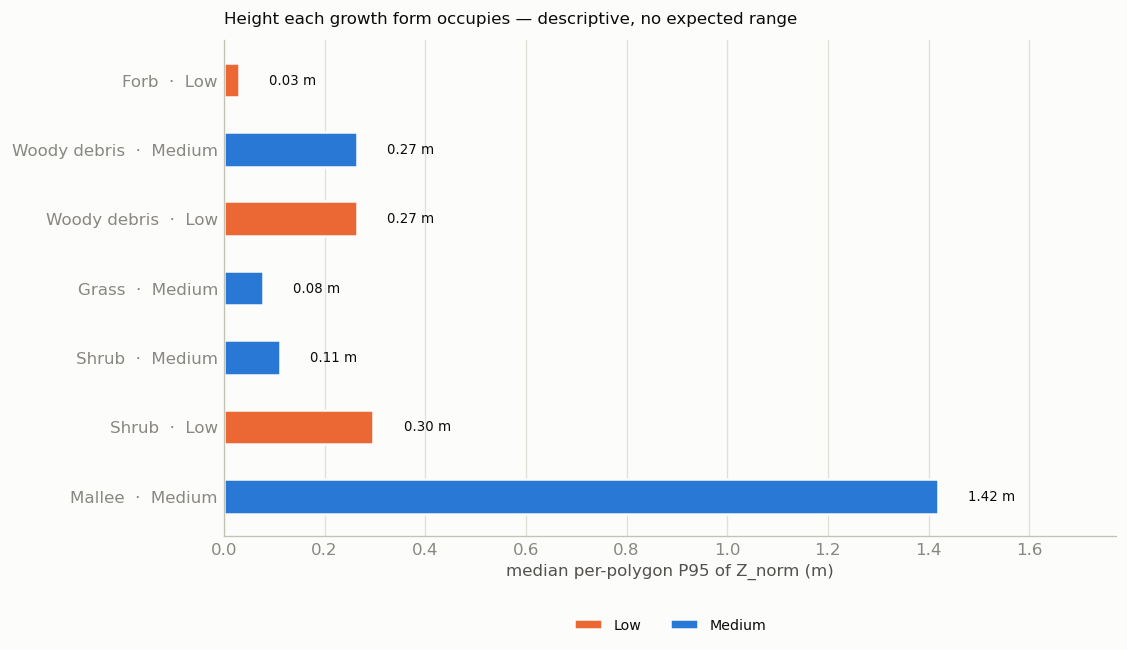

 Medium: 3.4% of polygons carry fewer than 10 returns and are excluded
    Low: 5.0% of polygons carry fewer than 10 returns and are excluded


In [ ]:
# One row per (class, site) that has height data.
entries = [(n, c) for n in CLASS_LABELS.values() for c in CONDITIONS
           if pd.notna(DATA[c]['avg'].get(f'P95 Znorm {n} (m)'))]

fig, ax = plt.subplots(figsize=(9.5, 0.52 * len(entries) + 1.9))
seen = set()
for i, (name, cond) in enumerate(entries):
    med = DATA[cond]['avg'][f'P95 Znorm {name} (m)']
    auc = DATA[cond]['avg'].get(f'Height AUC {name}')
    ax.barh(i, med, height=0.5, color=COLOUR[cond], edgecolor=SURFACE, linewidth=1.5,
            label=cond if cond not in seen else None)
    seen.add(cond)
    tag = f'{med:.2f} m' + (f'   AUC {auc:.2f}' if pd.notna(auc) else '   AUC n/a')
    ax.text(med + 0.06, i, tag, va='center', ha='left', color=INK, fontsize=8)

ax.set_yticks(np.arange(len(entries)),
              [f'{name}  ·  {cond}' for name, cond in entries])
ax.invert_yaxis()
ax.set_xlim(0, max(DATA[c]['avg'][f'P95 Znorm {n} (m)'] for n, c in entries) * 1.35)
ax.set_xlabel(f'median per-polygon P{CANOPY_PERCENTILE} of Z_norm (m)')
ax.set_title('Height each growth form occupies, with its separation from the other classes',
             loc='left', fontsize=10, pad=10)
ax.legend(ncols=2, loc='upper center', bbox_to_anchor=(0.5, -0.14), fontsize=8.5)
tidy(ax)
plt.tight_layout()
plt.show()

for cond in CONDITIONS:
    print(f"{cond:>7}: {DATA[cond]['avg']['Polygons with too few returns (%)']:.1f}% of polygons "
          'carry fewer than 10 returns and are excluded')


---
## 9. Issues logged, per polygon

`<site>_qa_issues.csv` records every problem individually, so a flagged polygon can be opened in
QGIS by tile and row index. Counts rather than a chart: the categories span three orders of
magnitude and read better as a table.


In [10]:
counts = pd.DataFrame({c: DATA[c]['issues']['Issue'].value_counts() for c in CONDITIONS})
counts = counts.fillna(0).astype(int)
counts.index.name = 'Issue'
counts['Per tile (Medium)'] = (counts['Medium'] / len(DATA['Medium']['per_tile'])).round(1)
counts['Per tile (Low)'] = (counts['Low'] / len(DATA['Low']['per_tile'])).round(1)
display(counts.sort_values('Medium', ascending=False))
display(DATA['Low']['issues']
        .query("Issue == 'raster_disagrees_with_shapefile'")
        .head(3)[['Tile', 'Issue', 'Details']])

,Medium,Low,Per tile (Medium),Per tile (Low)
Issue,,,,
height_implausible,1262,3064,84.1,204.3
too_few_lidar_points,182,331,12.1,22.1
overlap_different_class,128,308,8.5,20.5
invalid_geometry,114,12,7.6,0.8
small_area,85,42,5.7,2.8
overlap_same_class,72,1909,4.8,127.3
grid_misaligned_5cm,13,0,0.9,0.0
raster_disagrees_with_shapefile,0,13,0.0,0.9


,Tile,Issue,Details
166,25,raster_disagrees_with_shapefile,Woody debris: IoU 0.000 between the 1 polygons...
636,30,raster_disagrees_with_shapefile,Woody debris: IoU 0.000 between the 1 polygons...
971,31,raster_disagrees_with_shapefile,Woody debris: IoU 0.000 between the 1 polygons...


---
## 10. Findings to settle before reporting

Each is stated with the measurement that establishes it. Nothing here is asserted without a cell
above or below that produces the number.


### 10.1 The medium site's 5 cm labels are dilated

Established in section 6: 13 of 15 tiles carry a 5 cm grid offset by 1–4 cm from their 1 cm grid,
and those tiles gain 9.6–14.1% labelled area, concentrated in the thinnest classes. The two tiles
whose grids align gain 0.02–0.04%. The extra cells are verified as neighbour dilation, not
different source material.

**Why it matters.** The models consume the 5 cm labels, so this bears directly on the reported
results.

**Fix.** Make the 5 cm grid a whole multiple of the 1 cm grid before warping — pad the 1 cm tile
to 3075 px, or pass `-tap` and drop `-srcnodata` so nodata decimates like any other value.


### 10.2 The low site's shapefiles disagree with its rasters

`EXCLUDE_CLASSES` in `2_1_structure_2D_labels.py` contains the typo `'unknowm'`, so `'unknown'`
never matches the exclusion list. The cell below measures what that left behind.


In [11]:
import geopandas as gpd

shp_dir = DATA['Low']['paths']['shp']
rows = []
for shp in sorted(shp_dir.glob('*.shp'), key=lambda p: int(p.stem.split('.')[-1])):
    gdf = gpd.read_file(shp)
    gdf['struct_id'] = gdf['struct_id'].astype(int)
    one = gdf[gdf['struct_id'] == 1]
    unknown = one[one['structure'] == 'unknown']
    rows.append({'Tile': shp.stem.split('.')[-1],
                 'unknown polygons': len(unknown),
                 'their area (m2)': round(float(unknown.geometry.area.sum()), 1),
                 'genuine woody-debris area (m2)':
                     round(float(one[one['structure'] != 'unknown'].geometry.area.sum()), 3)})
u = pd.DataFrame(rows)
tile_area = 30.72 * 30.72
print(f"{u['unknown polygons'].sum()} `unknown` polygons carry struct_id 1 (Woody debris), "
      f"{u['their area (m2)'].sum():.0f} m² in total, "
      f"mean {u['their area (m2)'].sum() / max(u['unknown polygons'].sum(), 1):.0f} m² each "
      f"= {u['their area (m2)'].sum() / max(u['unknown polygons'].sum(), 1) / tile_area * 100:.1f}% of a tile.")
print(f"Genuine woody-debris content at this site: "
      f"{u['genuine woody-debris area (m2)'].sum():.1f} m² in total.")
display(u)

13 `unknown` polygons carry struct_id 1 (Woody debris), 1550 m² in total, mean 119 m² each = 12.6% of a tile.
Genuine woody-debris content at this site: 10.4 m² in total.


,Tile,unknown polygons,their area (m2),genuine woody-debris area (m2)
0,25,1,127.1,0.000
1,30,1,141.8,0.000
2,31,1,94.3,0.000
3,33,1,167.1,4.406
4,39,1,105.2,0.000
5,41,1,118.4,0.000
6,43,1,144.2,0.000
7,48,1,26.1,4.882
8,52,1,62.9,0.000
9,58,1,131.3,0.232


The delivered 1 cm rasters were built *after* those polygons were removed, which is why
`IoU raster Woody debris` is 0.014 rather than the ~0.85 the medium site shows: the shapefiles on
disk are not the version the rasters came from.

**The risk is forward-looking.** The rasters currently in use are correct. But re-running
`2_2_structure_2D_rasterLabels.py` over the shapefiles as they stand would inject a false
Woody-debris region covering an eighth of each affected tile. Fix the typo and re-export the
low-site shapefiles before any step is re-run from them.


### 10.3 The two sites do not share a definition of class 1

Section 4 shows the medium site has IDs 1–4 and no forbs, while the low site has IDs 0, 1 and 3
and no grass or mallee — **only classes 1 and 3 are common to both**, and class 1 is the one
affected by 10.2. The cell below adds the second reason class 1 differs, counted from the
committed step-2 logs.


In [12]:
import re

log_dir = REPO_ROOT / 'phase_3_2D_imagery_prep' / 'step_2_structure_2D_labels' / 'logs'
for log in sorted(log_dir.glob('*.txt')):
    text = log.read_text(encoding='utf-8', errors='replace')
    mapped = sum(int(m) for m in re.findall(r"- litter -> ID 1: (\d+) polygons", text))
    dropped = sum(int(m) for m in re.findall(r"- 'litter': (\d+) polygons", text))
    site = 'low' if '_low_' in log.name else 'medium'
    print(f'{site:>7} site log: litter mapped into ID 1 = {mapped:>4}, '
          f'litter dropped as unrecognised = {dropped:>4}')

    low site log: litter mapped into ID 1 =    1, litter dropped as unrecognised =    0
 medium site log: litter mapped into ID 1 =    0, litter dropped as unrecognised =  752


`'litter': 1` is commented out at line 14 of `2_1_structure_2D_labels.py`. The low-site labels
were produced while it was active, the medium-site labels after it was disabled — so the two runs
did not use the same definition of ID 1.

**The consequence is one-sided.** The low site contained just **1** litter polygon, so folding it
in changed almost nothing there. The medium site contained **752**, all dropped. So ID 1 means
"woody debris, litter excluded" at the medium site and "woody debris plus litter" at the low site,
but only the medium site lost material to the choice. Either re-run one site so both use the same
mapping, or state the exclusion explicitly in the manuscript. This is a decision about label
semantics, so it has deliberately not been changed in code.


### 10.4 Neither site's labels interlock with the imagery they are scored against

Established in section 7. The medium site's predictors are 5 cm like its labels, but their
origin sits 2 cm off the label grid, so every label is read against a pixel it only partly
covers. The low site's predictors are **6 cm** against 5 cm labels — same origin, but 1.2 label
cells per pixel, so the two tensors cannot be indexed together at all without resampling one of
them again.

This is unlike 10.1–10.3: it is not a defect in the annotation, it is a defect in how the
annotation is *delivered* to the model. A reviewer asking about label quality is entitled to it,
because it limits the accuracy any model could reach regardless of how good the labels are.

**Fix.** Warp the labels onto the predictor grid — `gdalwarp -te` and `-ts` taken from the
predictor tile — rather than onto a round 5 cm. That subsumes the 10.1 fix.


### 10.5 The height columns depend on each site's LiDAR being its own

DD0011's LiDAR directory once held a copy of DD0001's tiles. The two sites' tile IDs do not
overlap (DD0001 is 16–205, DD0011 is 25–79), so the copy produced blank height columns rather
than wrong ones — but only by luck. The guard below re-checks the tile match on every run, and
the height section above is only readable if it passes.


In [14]:
for cond in CONDITIONS:
    las_dir = DATA[cond]['paths']['las']
    tile_ids = sorted(DATA[cond]['per_tile']['Tile'].astype(str), key=int)
    if not las_dir.exists():
        print(f'{cond:>7}: {las_dir} does not exist — 0 of {len(tile_ids)} tiles have LAS')
        continue
    las_ids = sorted({p.stem.split('.')[-1] for p in las_dir.glob('*.las')}, key=int)
    overlap = sorted(set(tile_ids) & set(las_ids), key=int)
    print(f'{cond:>7}: {len(las_ids)} LAS files present. '
          f'label tiles {tile_ids[:4]}…  LAS tiles {(las_ids[:4] or ["none"])}…  '
          f'matching = {len(overlap)}/{len(tile_ids)}')

 Medium: 15 LAS files present. label tiles ['16', '22', '26', '55']…  LAS tiles ['16', '22', '26', '55']…  matching = 15/15
    Low: 15 LAS files present. label tiles ['25', '30', '31', '33']…  LAS tiles ['25', '30', '31', '33']…  matching = 15/15


---
## 11. What stands in for reproducibility

Nothing above answers *"would a second annotator draw the same thing?"*, and nothing can without
a second annotator. **No repeat delineation was made, and none is claimed here.**

What *is* measurable from the delivered labels alone is how much a different outline could
change. `label_qa.py` erodes and dilates each class by 5 cm — one cell at the resolution the
models consume — and takes the IoU between the two. That is the agreement two delineations
disagreeing by 5 cm **everywhere, in every direction** would still reach, so it is a floor rather
than an estimate:

- a class at **0.8** cannot be moved far by where the line went, whoever drew it, so a reviewer
  cannot attribute its model scores to annotator subjectivity;
- a class at **0.3** is thin or fragmented relative to 5 cm, so most of it *is* boundary, and its
  scores should be read as sensitive to delineation by construction.

Beside it, the share of labelled area lying within 5 cm of a *different* class — the places where
a shifted line changes which class a pixel reports, rather than only whether it is labelled at
all. Read together with the cross-class overlap from section 3, the pair brackets the ambiguity
from both sides: overlap is ambiguity the annotator **did** leave behind, delineation IoU is
ambiguity they **could** introduce.


In [ ]:
present_edge = [n for n in CLASS_LABELS.values()
                if any(pd.notna(DATA[c]['avg'].get(f'Delineation IoU {n}')) for c in CONDITIONS)]

fig, ax = plt.subplots(figsize=(9.5, 0.55 * len(present_edge) + 2.1))
y = np.arange(len(present_edge))
h = 0.34
for k, cond in enumerate(CONDITIONS):
    vals = [DATA[cond]['avg'].get(f'Delineation IoU {n}') for n in present_edge]
    edges = [DATA[cond]['avg'].get(f'Edge share {n} (%)') for n in present_edge]
    pos = y + (k - (len(CONDITIONS) - 1) / 2) * h
    finite = [(p, v) for p, v in zip(pos, vals) if pd.notna(v)]
    if finite:
        ax.barh([p for p, _ in finite], [v for _, v in finite], height=h * 0.88,
                color=COLOUR[cond], label=cond, edgecolor=SURFACE, linewidth=1.5)
    for p, v, e in zip(pos, vals, edges):
        if pd.isna(v):
            ax.text(0.01, p, 'not present', va='center', ha='left',
                    color=MUTED, fontsize=7.5, style='italic')
        else:
            ax.text(v + 0.015, p, f'{v:.3f}   {e:.0f}% is edge', va='center', ha='left',
                    color=INK if v >= 0.5 else '#d03b3b', fontsize=8)
ax.axvline(1.0, color=AXIS, linewidth=0.8, linestyle=(0, (3, 3)), zorder=0)
ax.set_xlim(0, 1.3)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_yticks(y, present_edge)
ax.invert_yaxis()
ax.set_xlabel(f'IoU between the class eroded and dilated by {BOUNDARY_CM:.0f} cm')
ax.set_title(f'Worst-case agreement of two delineations differing by {BOUNDARY_CM:.0f} cm',
             loc='left', fontsize=10, pad=10)
ax.legend(ncols=2, loc='upper center', bbox_to_anchor=(0.5, -0.16), fontsize=9)
tidy(ax)
plt.tight_layout()
plt.show()

for cond in CONDITIONS:
    a = DATA[cond]['avg']
    print(f"{cond:>7}: {a['Labelled area near a class boundary (%)']:5.1f}% of labelled area lies "
          f"within {BOUNDARY_CM:.0f} cm of a different class, against "
          f"{a['Cross-class overlap (%)']:.3f}% already ambiguous through overlap")


 Medium: no repeat annotation at /tmp/wsl_drive_d/paper2/data/calperumResearch/site1_1_DD0001/imagery/inputs/masks/tiles_3072/raw/structure_class/annotations_shp_reannotation — skipping
    Low: no repeat annotation at /tmp/wsl_drive_d/paper2/data/calperumResearch/site2_1_DD0011/imagery/inputs/masks/tiles_3072/raw/structure_class/annotation_shp_reannotation — skipping


### The residual limitation, stated plainly

Delineation sensitivity bounds the *geometric* half of annotator disagreement. It says nothing
about the *semantic* half — two interpreters drawing the same outline and calling it different
things. Three measures on this page bear on that half indirectly and none of them settles it:

| | What it supports | What it still does not rule out |
|---|---|---|
| Cross-class overlap (§3) | the annotator rarely left a pixel with two classes | that the single class chosen was the one another interpreter would choose |
| Height AUC (§8) | the classes differ on a measurement the annotator never saw | that a *particular* polygon is in the right class |
| Delineation IoU (§11) | outline placement cannot account for much of the class | anything about class assignment |

The honest form of the answer to the reviewer is therefore: the labels are internally consistent,
their geometry is well behaved, they survive the pipeline with the exceptions in §10.1 and §10.2,
and they separate on independent LiDAR structure — but they are **not registered to the imagery
they are scored against** (§10.4), and their reproducibility is **unquantified**. Quantifying it
would take a second delineation of the same tiles, which was not made; §11 is what is offered in
its place.
